# Práctica 3 · Etapa 3 — Partición temporal y líneas base

**3201 Modelos Inteligentes de Aprendizaje / 529 Redes Neuronales Modulares** · Maestría y Doctorado en Ciencias e Ingeniería (MyDCI) · Facultad de Ingeniería, Arquitectura y Diseño ·
Universidad Autónoma de Baja California · Ciclo 2026-2 · Versión 6

**Profesores:** Dr. Everardo Inzunza González · Dr. Enrique Efrén García Guerrero · Dr. Oscar Adrián Aguirre Castro

**Fase 3 de la sesión** · presupuesto: **15 min**

---

Un pronóstico se evalúa con datos que el modelo **no vio** y que, además, están **en el futuro** respecto de los que usó para aprender. Esta etapa parte la tabla supervisada en entrenamiento, validación y prueba **sin barajar**, mide dentro del desarrollo qué pasa si se baraja, y calcula tres **líneas base** en validación: reglas simples que todo modelo debe superar para justificar su existencia. El bloque de prueba sigue reservado: sus líneas base se calculan en la Etapa 5, junto con los modelos.

| Necesita | Produce |
|---|---|
| `artefactos/caracteristicas_2038.csv` (Etapa 2) | Tablas E y F · figura F7 · `artefactos/particion_2038.json` y `artefactos/lineas_base_val_2038.csv` |

**Cómo leer este cuaderno.** Cada bloque abre con una celda de texto que explica *qué* se hace y *por qué*. Dentro del
código, el comentario a la derecha de cada instrucción dice para qué sirve esa línea. Las salidas marcadas con
**`← Anote`** son las que usted copia en la tabla indicada del manual; el resto sólo se ejecuta y se observa.
Ejecute las celdas **en orden**; si cambia algo, vuelva a ejecutar desde esa celda hacia abajo.

---
## Bloque 0 · Puesta en marcha

Esta celda se ejecuta **siempre primero**, en cualquier entorno. Detecta si está en Google Colab, en el JupyterHub del
laboratorio o en un Jupyter local; localiza la carpeta de la práctica (`P3_SeriesTiempo_v6`, la que descargó de
Classroom); crea `resultados/` con sus subcarpetas sin borrar nada; instala sólo lo que falte; fija la semilla e imprime
las versiones con que se ejecutó. Reproducir un resultado empieza por saber con qué se obtuvo.

> **En Colab**, cada cuaderno corre en su propia máquina virtual: los archivos que un cuaderno guarda sólo los ve el
> siguiente si viven en **Google Drive**. Por eso la carpeta de la práctica se sube a *Mi unidad* y esta celda la monta.

In [1]:
# ── Bloque 0 · Puesta en marcha (Etapa 3) ─────────────────────────────────────────────
import sys, os, json, time, hashlib, warnings, subprocess, importlib  # utilidades estándar de Python
from pathlib import Path                                   # rutas que funcionan igual en Windows, Linux y Colab
T0 = time.perf_counter()                                   # cronómetro de este cuaderno
warnings.filterwarnings("ignore", category=FutureWarning)  # oculta sólo avisos de versiones futuras

try:
    import google.colab                                    # este módulo sólo existe dentro de Google Colab
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

CARPETA_PRACTICA = "P3_SeriesTiempo_v6"                    # la carpeta que descargó de Classroom
if EN_COLAB:
    from google.colab import drive                         # acceso a Google Drive desde Colab
    drive.mount("/content/drive")                          # la primera vez pide autorización
    RAIZ_DRIVE = Path("/content/drive/MyDrive")            # «Mi unidad»
    candidatas = [RAIZ_DRIVE / CARPETA_PRACTICA, RAIZ_DRIVE / "Colab Notebooks" / CARPETA_PRACTICA]
    candidatas += sorted(RAIZ_DRIVE.glob(f"*/{CARPETA_PRACTICA}"))  # también un nivel más abajo
else:
    aqui = Path.cwd().resolve()                            # carpeta desde donde se abrió el cuaderno
    candidatas = [aqui, *aqui.parents][:4]                 # el cuaderno vive en notebooks/: se busca hacia arriba
    candidatas += [p / CARPETA_PRACTICA for p in candidatas]
BASE = next((c for c in candidatas if (c / "datos").is_dir() and (c / "notebooks").is_dir()), None)
if BASE is None:
    raise FileNotFoundError("No encuentro la carpeta de la práctica (con datos/ y notebooks/). "
                            "Revise la Sección 4.3 del manual: en Colab súbala completa a «Mi unidad».")
DATOS, RES = BASE / "datos", BASE / "resultados"           # entradas y salidas de la práctica
FIG, TAB, ART = RES / "figuras", RES / "tablas", RES / "artefactos"  # figuras · tablas · archivos intermedios
for carpeta in (FIG, TAB, ART):
    carpeta.mkdir(parents=True, exist_ok=True)             # se crean si faltan; nunca se borra nada

# Bibliotecas: se instala sólo lo que falte (en Colab casi todo viene preinstalado).
NECESARIAS = {"numpy": "numpy", "pandas": "pandas", "sklearn": "scikit-learn", "xgboost": "xgboost",
               "matplotlib": "matplotlib", "seaborn": "seaborn", "statsmodels": "statsmodels",
               "openpyxl": "openpyxl", "scipy": "scipy"}
for modulo, paquete in NECESARIAS.items():
    try:
        importlib.import_module(modulo)                    # ¿ya está instalado?
    except ImportError:
        print("Instalando", paquete, "…")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", paquete], check=True)

import numpy as np                                         # cálculo numérico con arreglos
import pandas as pd                                        # tablas de datos indexadas por fecha
import matplotlib                                          # motor de gráficas
import matplotlib.pyplot as plt                            # interfaz de gráficas
import sklearn, xgboost as xgb                             # scikit-learn y XGBoost
import seaborn, statsmodels, scipy                         # sólo para registrar sus versiones aquí

def _ver(v):
    return tuple(int("".join(ch for ch in p if ch.isdigit()) or 0) for p in v.split(".")[:2])
assert _ver(sklearn.__version__) >= (1, 4), "Se necesita scikit-learn ≥ 1.4 (root_mean_squared_error)."
assert _ver(xgb.__version__) >= (2, 0), "Se necesita XGBoost ≥ 2.0 (early_stopping_rounds en el constructor)."

SEMILLA = 42                                               # una sola semilla para toda la práctica
np.random.seed(SEMILLA)                                    # fija el azar de numpy
pd.set_option("display.width", 160)                        # tablas anchas sin cortes de renglón
pd.set_option("display.max_columns", 30)
COLORES = {"real": "#15241E", "XGBoost": "#17795C", "SVR": "#D9A21B", "Random Forest": "#9E2B25",
            "Ingenuo": "#9AA7A1", "Ingenuo estacional": "#5E6E67", "Climatología": "#165542"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})  # estilo uniforme de las figuras

def guardar(fig, nombre):
    """Guarda la figura en resultados/figuras/ (PNG, 150 dpi) para insertarla en el manual."""
    ruta = FIG / f"{nombre}.png"
    fig.savefig(ruta, dpi=150, bbox_inches="tight")
    print("Figura guardada →", ruta.relative_to(BASE))

def _serializable(v):
    """Convierte tipos de numpy y pandas a tipos de Python; los no finitos (NaN, ±inf) quedan como None."""
    if isinstance(v, dict):
        return {str(k): _serializable(x) for k, x in v.items()}
    if isinstance(v, (list, tuple)):
        return [_serializable(x) for x in v]
    if isinstance(v, (bool, np.bool_)):
        return bool(v)
    if isinstance(v, (int, np.integer)):
        return int(v)
    if isinstance(v, (float, np.floating)):
        return float(v) if np.isfinite(v) else None
    if isinstance(v, pd.Timestamp):
        return v.isoformat()
    return v

def registrar(clave, valor):
    """Añade un resultado a resultados/registro_P3.json (se acumula entre cuadernos; JSON estricto, sin NaN)."""
    ruta = RES / "registro_P3.json"
    reg = json.loads(ruta.read_text(encoding="utf-8")) if ruta.exists() else {}
    reg[clave] = _serializable(valor)
    ruta.write_text(json.dumps(reg, ensure_ascii=False, indent=1, allow_nan=False), encoding="utf-8")

def md5(ruta):
    return hashlib.md5(Path(ruta).read_bytes()).hexdigest()  # huella del archivo

if EN_COLAB:
    ENTORNO = "Google Colab"
elif "JUPYTERHUB_USER" in os.environ:
    ENTORNO = "JupyterHub"                                 # sesión abierta en el JupyterHub del laboratorio
elif "ai_env" in sys.executable:
    ENTORNO = "Kernel ai_env del laboratorio"              # el mismo kernel, fuera de una sesión del Hub
else:
    ENTORNO = "Jupyter local"
VERSIONES = {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__,
              "scikit-learn": sklearn.__version__, "xgboost": xgb.__version__, "matplotlib": matplotlib.__version__,
              "seaborn": seaborn.__version__, "statsmodels": statsmodels.__version__, "scipy": scipy.__version__}
registrar("etapa3_entorno", {"entorno": ENTORNO, **VERSIONES})
print("Entorno        :", ENTORNO)                         # ← Anote (Tabla A)
print("Carpeta base   :", BASE)
for k, v in VERSIONES.items():
    print(f"{k:<15}:", v)                                  # ← Anote (Tabla A): Python, scikit-learn, XGBoost y pandas

Entorno        : Jupyter local
Carpeta base   : C:\Users\Diana\git\Course_RedesNeuronales_2026\PR3_TimeSeries\P3_SeriesTiempo_v6
python         : 3.12.15
numpy          : 2.5.4
pandas         : 3.1.0
scikit-learn   : 1.9.1
xgboost        : 3.4.1
matplotlib     : 3.11.2
seaborn        : 0.13.2
statsmodels    : 0.15.0
scipy          : 1.18.1


In [2]:
ruta = ART / "caracteristicas_2038.csv"
if not ruta.exists():
    raise FileNotFoundError("Falta caracteristicas_2038.csv: ejecute primero el cuaderno de la Etapa 2.")
tabla = pd.read_csv(ruta, index_col="FECHA", parse_dates=True)  # X + y de la Etapa 2
y = tabla.pop("y")  # separa el objetivo…
X = tabla           # …de las características
print("Tabla supervisada:", X.shape, "· objetivo:", y.shape)

Tabla supervisada: (1031, 8) · objetivo: (1031,)


---
## 3.1 Partición hold-out que respeta el tiempo

`train_test_split` sólo produce dos subconjuntos, así que se aplica dos veces: primero 70/30 y luego el 30 % restante
a la mitad. El parámetro **`shuffle=False` es obligatorio**: conserva el orden, de modo que entrenamiento es el pasado,
validación el periodo siguiente y prueba el más reciente.

| Subconjunto | Proporción | Para qué se usa |
|---|---|---|
| Entrenamiento | 70 % | ajustar los parámetros de cada modelo |
| Validación | 15 % | elegir hiperparámetros y comparar configuraciones |
| Prueba | 15 % | estimar el desempeño final **una sola vez** (Etapa 5) |

In [3]:
from sklearn.model_selection import train_test_split
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.30, shuffle=False)  # 70 % | 30 %
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, shuffle=False)  # 15 % | 15 %

assert X_train.index.max() < X_val.index.min() < X_test.index.min(), "¡La partición no está en orden!"  # sin traslapes
partes = {"entrenamiento": y_train, "validación": y_val, "prueba": y_test}
for nombre, parte in partes.items():
    print(f"{nombre:<14}: {len(parte):4d} meses · {parte.index[0]:%Y-%m} a {parte.index[-1]:%Y-%m} "
          f"· {len(parte) / len(y):.1%}")  # ← Anote (Tabla E)
X_des, y_des = pd.concat([X_train, X_val]), pd.concat([y_train, y_val])  # desarrollo = entrenamiento + validación

entrenamiento :  721 meses · 1940-01 a 2000-05 · 69.9%
validación    :  155 meses · 2000-06 a 2013-04 · 15.0%
prueba        :  155 meses · 2013-05 a 2026-04 · 15.0%


Figura guardada → resultados\figuras\F07_est2038_particion.png


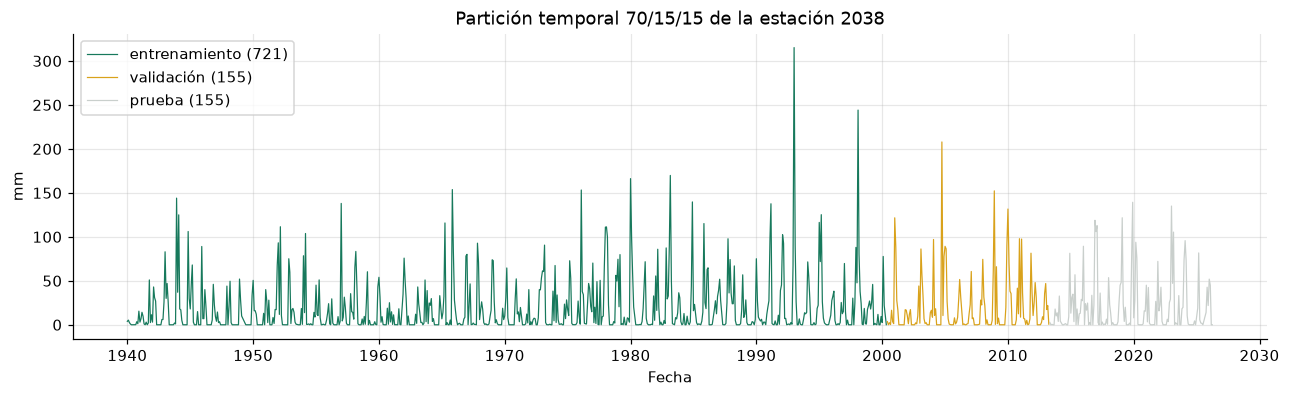

In [4]:
fig, ax = plt.subplots(figsize=(14, 3.6))
for (nombre, parte), color in zip(partes.items(), ["#17795C", "#D9A21B", "#C9CFCC"]):
    ax.plot(parte.index, parte.values, lw=0.8, color=color, label=f"{nombre} ({len(parte)})")  # la prueba, en gris
ax.set(title="Partición temporal 70/15/15 de la estación 2038", xlabel="Fecha", ylabel="mm")
ax.legend(loc="upper left")
guardar(fig, "F07_est2038_particion")  # → Figura F7 del manual
plt.show()

---
## 3.2 Experimento rápido: ¿qué cambia si se baraja?

Con `shuffle=True` los meses que se evalúan quedan intercalados con los de entrenamiento: el modelo aprende con meses
**posteriores** a los que luego «pronostica». Eso ya no es un pronóstico, y en series con mucha dependencia entre
instantes vecinos puede producir estimaciones optimistas (si en el consumo horario de la Etapa 1 el RMSE barajado le
salió menor, ése es el mecanismo). Pero la respuesta empírica depende de la serie: Bergmeir, Hyndman y Koo (2018) mostraron que, en modelos
autorregresivos cuyos residuos no están correlacionados, la validación con barajado puede ser válida. En vez de
predecir el resultado, la celda lo mide **dentro del desarrollo** —la prueba sigue reservada—: compara el R² de una
partición temporal (el último 15 % del desarrollo) con el de **20** particiones barajadas del mismo desarrollo (una
por semilla), todas con el mismo tamaño de evaluación.

In [5]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
Xa, Xb, ya, yb = train_test_split(X_des, y_des, test_size=0.15, shuffle=False)  # el 15 % más reciente del desarrollo
rf = RandomForestRegressor(n_estimators=100, random_state=SEMILLA, n_jobs=-1).fit(Xa, ya)
r2_temporal = r2_score(yb, rf.predict(Xb))
r2_barajado = []
for semilla in range(20):  # 20 particiones barajadas distintas
    Xa, Xb, ya, yb = train_test_split(X_des, y_des, test_size=0.15, shuffle=True, random_state=semilla)
    rf = RandomForestRegressor(n_estimators=100, random_state=SEMILLA, n_jobs=-1).fit(Xa, ya)
    r2_barajado.append(r2_score(yb, rf.predict(Xb)))
r2_barajado = np.array(r2_barajado)
print(f"R² partición temporal (desarrollo) : {r2_temporal:.3f}")  # ← Anote (Tabla E)
print(f"R² barajado (20 semillas)          : {r2_barajado.mean():.3f} ± {r2_barajado.std():.3f} "
      f"(mín {r2_barajado.min():.3f}, máx {r2_barajado.max():.3f})")  # ← Anote (Tabla E: media ± DE; mín–máx opcional)
print("¿Alguna semilla barajada supera al temporal?", bool((r2_barajado > r2_temporal).any()),
      "· ¿todas lo superan?", bool((r2_barajado > r2_temporal).all()))  # lo que diga aquí es lo que debe interpretar

R² partición temporal (desarrollo) : 0.129
R² barajado (20 semillas)          : 0.100 ± 0.088 (mín -0.153, máx 0.290)
¿Alguna semilla barajada supera al temporal? True · ¿todas lo superan? False


> **Cómo leerlo.** Hay tres salidas posibles y las tres enseñan algo. Si las 20 semillas barajadas quedan **por
> encima** del temporal, barajar infló el resultado: el modelo interpoló entre meses vecinos. Si quedan **por debajo**,
> barajar no infló nada en esta serie; lo que cambió es *qué* meses se evalúan (una muestra de todo el periodo frente
> a los años más recientes) y con qué media se calcula el R², y conviene revisar la ACF de rezago 1 que obtuvo en la
> Etapa 2: con poca memoria entre meses consecutivos hay poco que interpolar. Si unas quedan arriba y otras abajo, la
> cifra barajada depende de la semilla y por eso se reportan 20. En cualquiera de los tres casos la razón para **no**
> barajar es de protocolo, no empírica: el uso real del modelo es pronosticar **hacia adelante**, la serie puede
> cambiar con el tiempo (instrumento, registro, clima) y no se sabe de antemano si se cumple la condición de Bergmeir
> et al. (2018). La partición temporal es la que responde la pregunta que importa. Escriba en su reporte cuál de los
> tres casos observó y por qué.

---
## 3.3 Líneas base en validación: lo mínimo que un modelo debe superar

Tres **reglas simples**. Las dos primeras no estiman nada; la climatología estima doce medias (una por mes calendario)
y aun así es la referencia clásica en meteorología. Un RMSE o un R² no significan nada solos: significan algo
**comparados** con estas reglas.

| Línea base | Pronóstico de `y(t)` | Idea |
|---|---|---|
| Ingenuo (*naive*) | `y(t−1)` | «el próximo mes será como éste» |
| Ingenuo estacional | `y(t−12)` | «será como el mismo mes del año pasado» |
| Climatología | media del mismo mes calendario en los datos de ajuste | «será un mes típico» |

Aquí se evalúan **sólo en validación**, con la climatología calculada con el entrenamiento. Las mismas tres reglas se
evaluarán en la prueba en la Etapa 5, el único momento en que ese bloque se abre, con la climatología calculada con
entrenamiento + validación (igual que se reentrenarán los modelos).

In [6]:
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

def climatologia(y_ajuste, indice):
    """Media de cada mes calendario en y_ajuste, asignada a las fechas de `indice`."""
    medias = y_ajuste.groupby(y_ajuste.index.month).mean()  # 12 valores, uno por mes
    return pd.Series(medias.reindex(indice.month).values, index=indice)

base_val = {"Ingenuo": X_val["lag_1"],                      # y(t−1): el rezago 1 ya está alineado por fecha
            "Ingenuo estacional": X_val["lag_12"],          # y(t−12)
            "Climatología": climatologia(y_train, X_val.index)}  # medias del entrenamiento, nada posterior
filas = []
for nombre, p in base_val.items():
    filas.append({"línea base": nombre, "n": int(len(y_val)),
                  "RMSE_val": root_mean_squared_error(y_val, p),  # penaliza más los errores grandes
                  "MAE_val": mean_absolute_error(y_val, p),  # error típico en mm
                  "R2_val": r2_score(y_val, p)})            # reducción relativa del error cuadrático frente a la media de validación
tabla_F = pd.DataFrame(filas).set_index("línea base").round(3)
tabla_F                                                     # ← Anote (Tabla F): las tres filas

,n,RMSE_val,MAE_val,R2_val
línea base,,,,
Ingenuo,155,40.287,21.435,-0.444
Ingenuo estacional,155,41.141,21.289,-0.505
Climatología,155,28.751,15.811,0.265


> **Lea el signo del R².** Un R² negativo significa que la regla lo hace **peor que predecir siempre la media del
> bloque evaluado**. No es un error de cálculo: con lluvias intermitentes, copiar el mes anterior falla mucho al pasar
> de un mes seco a uno lluvioso.

In [7]:
import json
particion = {nombre: {"n": int(len(p)), "desde": f"{p.index[0]:%Y-%m}", "hasta": f"{p.index[-1]:%Y-%m}",
                      "fechas": [f"{t:%Y-%m}" for t in p.index]}  # la lista completa, para comparar fecha por fecha
             for nombre, p in partes.items()}
(ART / "particion_2038.json").write_text(json.dumps(particion, ensure_ascii=False, indent=1), encoding="utf-8")
pd.DataFrame(base_val).to_csv(ART / "lineas_base_val_2038.csv", index_label="FECHA")  # pronósticos en validación
registrar("etapa3", {"particion": {k: {kk: vv for kk, vv in v.items() if kk != "fechas"} for k, v in particion.items()},
                     "n_desarrollo": int(len(y_des)),
                     "r2_rf_temporal": round(r2_temporal, 4),
                     "r2_rf_barajado_media": round(float(r2_barajado.mean()), 4),
                     "r2_rf_barajado_de": round(float(r2_barajado.std()), 4),
                     "r2_rf_barajado_min": round(float(r2_barajado.min()), 4),
                     "r2_rf_barajado_max": round(float(r2_barajado.max()), 4),
                     "barajado_alguno_supera": bool((r2_barajado > r2_temporal).any()),
                     "barajado_todos_superan": bool((r2_barajado > r2_temporal).all()),
                     "tabla_F": tabla_F.to_dict(orient="index")})
print("Guardados: particion_2038.json (con las fechas de cada bloque) y lineas_base_val_2038.csv")

Guardados: particion_2038.json (con las fechas de cada bloque) y lineas_base_val_2038.csv


---
## Cierre de la Etapa 3

> **Punto de verificación.** La Tabla E tiene los tamaños y fechas de los tres bloques (deben sumar el total de la tabla supervisada y no traslaparse), el R² temporal y la media ± DE del barajado; la Tabla F, las tres líneas base en validación. Anote cuál es la más difícil de vencer en validación: con ella se compararán los modelos en la Etapa 4 y, fijada de antemano, será la vara en la prueba.

**Siguiente:** abra `P3_E4_Modelos_y_Ajuste.ipynb`.

In [8]:
minutos = (time.perf_counter() - T0) / 60  # tiempo de pared desde el Bloque 0
registrar("etapa3_duracion_min", round(minutos, 2))
print(f"Etapa 3 terminada en {minutos:.1f} min · resultados en", RES.relative_to(BASE))  # ← Anote (Tabla A): duración

Etapa 3 terminada en 9.9 min · resultados en resultados
